# Sensitivity of filter feeders to macroaggregate sinking (`p_fMAsink`)

Runs GOTM-BFM for the OysterGrounds case once per value of `p_fMAsink`
(scaling factor for the macroaggregate sinking rate; 1 = unchanged model),
then plots the mean suspension-feeder biomass (`Y3c`) over one year:

* **(a)** annual mean `Y3c` against `p_fMAsink`, labelled with the % change from `p_fMAsink = 1`
* **(b)** daily `Y3c` through the year, one line per `p_fMAsink`

One year takes about 6 minutes per run.

## NaaVRE workflow

The notebook is split into three workflow components, plus a settings cell that is
**not** containerized:

```
[1 fMAsink values] --> (splitter) --> [2 run GOTM] --> (merger) --> [3 plot fMAsink]
   fMAsink_values: List               run_dirs: List                 figure + table
```

1. **fMAsink values**: turns `param_fMAsink_values` (text, e.g. `"1,2,3,4,5,6"`) into the
   list `fMAsink_values`.
2. **run GOTM**: one model run for each value it receives. Behind the splitter, every branch
   gets one value, so the runs go in parallel. It outputs `run_dirs`, the list of run folders
   (strings) under `/tmp/data/`.
3. **plot fMAsink**: the merger collects `run_dirs` from all branches into one list. The cell
   reads `OG.nc` from each folder, then makes the table and figure. The figure, table and
   `results_folder` (string) are saved to Cloud Storage, because NaaVRE clears `/tmp/data/`
   when the workflow finishes.

Notes:
* Model output must be under `/tmp/data/`: only that folder is shared between components.
* The splitter and merger only work on lists, so `fMAsink_values` and `run_dirs` are lists.
* Types to choose when containerizing: `fMAsink_values` = List, `run_dirs` = List;
  `param_*` = String or Integer as in the settings cell.
* Run interactively, the notebook works top to bottom as before: cell 2 then gets the whole
  list and runs the values in parallel itself.

In [2]:
# run GOTM
# ---
# NaaVRE:
#  cell:
#   inputs: []
#   outputs:
#    - run_dirs: List
#   params:
#    - param_year:
#       type: Integer
#       default_value: 1972
#    - param_var:
#       type: String
#       default_value: "Y3c"
#    - param_start:
#       type: String
#       default_value: "1972-01-01 00:00:00"
#    - param_stop:
#       type: String
#       default_value: "1973-01-01 00:00:00"
#    - param_fMAsink_values:
#       type: String
#       default_value: "1,2,3,4,5,6"
# ...


# Settings (do not containerize this cell)
# param_ values are the defaults of the workflow components; they can be changed when
# the workflow is submitted.
param_fMAsink_values = "1,2,3,4,5,6"   # comma-separated p_fMAsink values
param_start = "1972-01-01 00:00:00"
param_stop = "1973-01-01 00:00:00"
param_results_root = "/tmp/data/fMAsink"   # shared between workflow components
param_year = 1972            # year to average over
param_var = "Y3c"            # BFM variable in OG.nc, e.g. "jnetY3c" for net production
param_cloud_folder = "/home/jovyan/Cloud Storage/naa-vre-user-data/fMAsink"   # kept after the workflow

# fMAsink values
# Output fMAsink_values (List): one item per model run; feed it to the splitter.
fMAsink_values = [float(v) for v in str(param_fMAsink_values).replace(";", ",").split(",") if v.strip()]
print("p_fMAsink values:", fMAsink_values)

# run GOTM
# Input fMAsink_values (List): all values (interactive run) or one batch from the splitter.
# Output run_dirs (List of str): run folders under param_results_root; feed it to the merger.
import json
import os
import shutil
import subprocess
import sys
from concurrent.futures import ThreadPoolExecutor
import stat


def remove_tree(path):
    """Delete a file or folder. gotm-run copies the case from the read-only image, so
    its folders are read-only: add write permission (like chmod -R u+w) and retry."""
    def make_writable(func, p, exc_info):
        for q in (os.path.dirname(p), p):
            try:
                os.chmod(q, os.stat(q).st_mode | stat.S_IWUSR | stat.S_IRUSR | stat.S_IXUSR)
            except OSError:
                pass
        func(p)
    if os.path.isdir(path) and not os.path.islink(path):
        shutil.rmtree(path, onerror=make_writable)
    else:
        try:
            os.remove(path)
        except PermissionError:
            make_writable(os.remove, path, None)



batch = fMAsink_values if isinstance(fMAsink_values, (list, tuple)) else [fMAsink_values]
batch = [float(v) for v in batch]


def run_one(value):
    """One GOTM-BFM run with p_fMAsink = value; returns the run folder."""
    run_dir = os.path.join(param_results_root, "fMAsink_{:g}".format(value))
    if os.path.exists(run_dir):          # gotm-run needs a new or empty directory
        remove_tree(run_dir)
    os.makedirs(param_results_root, exist_ok=True)
    command = [
        GOTM_RUN,
        "--out", run_dir,
        "--start", param_start,
        "--stop", param_stop,
        "--set", "PelGlobal.nml:p_fMAsink={:g}".format(value),
    ]
    proc = subprocess.run(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    status = "finished" if proc.returncode == 0 else "FAILED (see {}/log.out)".format(run_dir)
    print("p_fMAsink = {:<4g} {}".format(value, status), flush=True)
    if proc.returncode != 0:
        print(proc.stdout.decode(errors="replace")[-2000:])
    return run_dir


# gotm-run is installed in the GOTM-BFM image (/usr/local/bin/gotm-run); stop here,
# before anything is deleted, if this kernel cannot find it
GOTM_RUN = shutil.which("gotm-run") or (
    "/usr/local/bin/gotm-run" if os.access("/usr/local/bin/gotm-run", os.X_OK) else None)
if GOTM_RUN is None:
    raise RuntimeError(
        "gotm-run not found. Run this notebook in the virtual lab built from the GOTM-BFM "
        "Dockerfile, not in this kernel ({}).".format(sys.prefix))
print("model:", GOTM_RUN)

# Empty the run folder first, so files from an earlier submission are not mixed in
if os.path.isdir(param_results_root) and os.listdir(param_results_root):
    print("Emptying", param_results_root)
    for name in os.listdir(param_results_root):
        remove_tree(os.path.join(param_results_root, name))
os.makedirs(param_results_root, exist_ok=True)

print("Starting {} run(s) from {} to {} ...".format(len(batch), param_start, param_stop), flush=True)
with ThreadPoolExecutor(max_workers=max(1, len(batch))) as pool:
    run_dirs = list(pool.map(run_one, batch))
print("run_dirs:", run_dirs)

p_fMAsink      mean Y3c    change
        1        943.48    +0.00%
        2        996.53    +5.62%
        3       1047.89   +11.07%
        4       1082.22   +14.71%
        5       1103.83   +17.00%
        6       1127.27   +19.48%
results_folder: /home/jovyan/Cloud Storage/naa-vre-user-data/fMAsink
figure: /home/jovyan/Cloud Storage/naa-vre-user-data/fMAsink/fMAsink_Y3c_1972.png


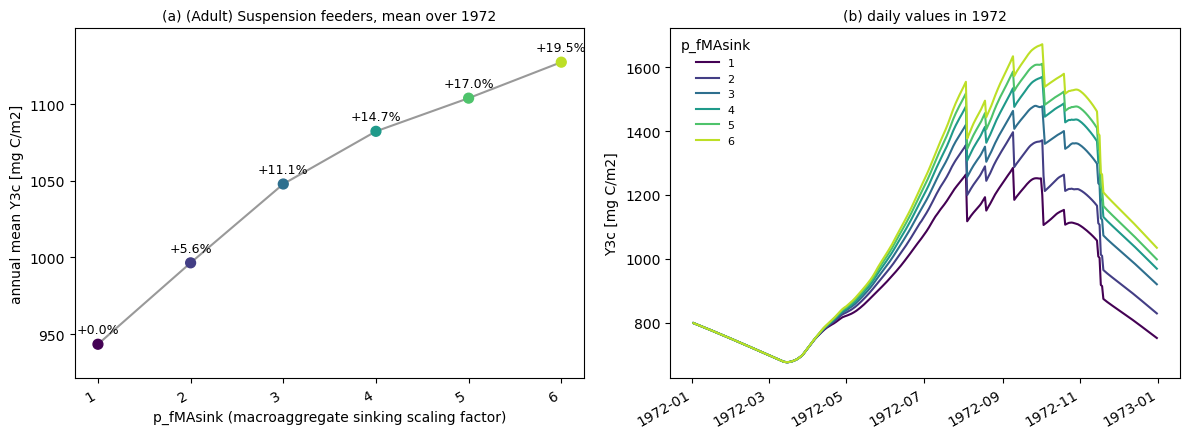

In [5]:
# plot fMAsink
# ---
# NaaVRE:
#  cell:
#   inputs:
#    - run_dirs: List
#   outputs:
#    - results_folder: String
#   params:
#    - param_year:
#       type: Integer
#       default_value: 1972
#    - param_var:
#       type: String
#       default_value: "Y3c"
#    - param_cloud_folder:
#       type: String
#       default_value: "/home/jovyan/Cloud Storage/naa-vre-user-data/fMAsink"
# ...

# plot fMAsink
# Input run_dirs (List of str): run folders from all branches (via the merger).
# Output results_folder (str): Cloud Storage folder with the figure and the table.
import datetime
import json
import os
import shutil

import matplotlib.pyplot as plt
import netCDF4
import numpy as np
import stat


def remove_tree(path):
    """Delete a file or folder. gotm-run copies the case from the read-only image, so
    its folders are read-only: add write permission (like chmod -R u+w) and retry."""
    def make_writable(func, p, exc_info):
        for q in (os.path.dirname(p), p):
            try:
                os.chmod(q, os.stat(q).st_mode | stat.S_IWUSR | stat.S_IRUSR | stat.S_IXUSR)
            except OSError:
                pass
        func(p)
    if os.path.isdir(path) and not os.path.islink(path):
        shutil.rmtree(path, onerror=make_writable)
    else:
        try:
            os.remove(path)
        except PermissionError:
            make_writable(os.remove, path, None)



# The merger may give a list of lists: flatten it
folders = []
for item in (run_dirs if isinstance(run_dirs, (list, tuple)) else [run_dirs]):
    folders.extend(item if isinstance(item, (list, tuple)) else [item])

year = int(param_year)
var = str(param_var)

results = []    # (p_fMAsink, dates, values)
units, long_name = "", var
for run_dir in folders:
    info_file = os.path.join(run_dir, "run_info.json")
    nc_file = os.path.join(run_dir, "OG.nc")
    if os.path.exists(info_file):
        with open(info_file) as f:
            if json.load(f).get("status") != "finished":
                print("skipped (run failed):", run_dir)
                continue
    if not os.path.exists(nc_file):
        print("skipped (no OG.nc):", run_dir)
        continue
    value = float(os.path.basename(os.path.normpath(run_dir)).split("_", 1)[1])
    with netCDF4.Dataset(nc_file) as nc:
        t = nc.variables["time"]
        # num2date may return cftime dates, which matplotlib cannot plot:
        # convert them to standard Python datetimes
        dates = [datetime.datetime(d.year, d.month, d.day, d.hour, d.minute, d.second)
                 for d in netCDF4.num2date(t[:], t.units)]
        values = np.ma.filled(nc.variables[var][:].reshape(len(dates), -1)[:, 0], np.nan)
        units = getattr(nc.variables[var], "units", "")
        long_name = getattr(nc.variables[var], "long_name", var)
    keep = np.array([d.year == year for d in dates])
    results.append((value, [d for d, k in zip(dates, keep) if k], values[keep]))
results.sort(key=lambda r: r[0])
if not results:
    raise RuntimeError("no finished runs in {}".format(folders))

# Annual mean and % change from p_fMAsink = 1 (or the closest value)
fs = np.array([r[0] for r in results], dtype=float)
means = np.array([np.nanmean(r[2]) for r in results])
ref = means[np.argmin(abs(fs - 1.0))]
change = 100.0 * (means - ref) / ref

table = ["p_fMAsink,mean_{},change_percent".format(var)]
print("{:>9}  {:>12}  {:>8}".format("p_fMAsink", "mean " + var, "change"))
for f, m, c in zip(fs, means, change):
    print("{:>9g}  {:>12.2f}  {:>+7.2f}%".format(f, m, c))
    table.append("{:g},{:.6g},{:.4f}".format(f, m, c))

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(results)))

ax1.plot(fs, means, "-", color="0.6", zorder=1)
ax1.scatter(fs, means, c=colors, s=50, zorder=2)
for f, m, c in zip(fs, means, change):
    ax1.annotate("{:+.1f}%".format(c), (f, m), textcoords="offset points",
                 xytext=(0, 8), ha="center", fontsize=9)
ax1.set_xlabel("p_fMAsink (macroaggregate sinking scaling factor)")
ax1.set_ylabel("annual mean {} [{}]".format(var, units))
ax1.set_title("(a) {}, mean over {}".format(long_name, year), fontsize=10)
ax1.set_xticks(fs)
ax1.margins(y=0.12)

for (f, dates, values), col in zip(results, colors):
    ax2.plot(dates, values, color=col, label="{:g}".format(f))
ax2.set_ylabel("{} [{}]".format(var, units))
ax2.set_title("(b) daily values in {}".format(year), fontsize=10)
ax2.legend(title="p_fMAsink", fontsize=8, frameon=False)
fig.autofmt_xdate()
fig.tight_layout()

# Save to Cloud Storage: /tmp/data is cleared when the workflow finishes
results_folder = str(param_cloud_folder)
# Empty the Cloud Storage folder first, so files from an earlier submission are not mixed in
if os.path.isdir(results_folder) and os.listdir(results_folder):
    print("Emptying", results_folder)
    for name in os.listdir(results_folder):
        remove_tree(os.path.join(results_folder, name))
os.makedirs(results_folder, exist_ok=True)
figure_file = os.path.join(results_folder, "fMAsink_{}_{}.png".format(var, year))
fig.savefig(figure_file, dpi=150)
with open(os.path.join(results_folder, "fMAsink_{}_{}.csv".format(var, year)), "w") as f:
    f.write("\n".join(table) + "\n")
for run_dir in folders:                  # keep the model logs and run info as well
    name = os.path.basename(os.path.normpath(run_dir))
    for fname in ("log.out", "run_info.json"):
        if os.path.exists(os.path.join(run_dir, fname)):
            os.makedirs(os.path.join(results_folder, name), exist_ok=True)
            shutil.copy(os.path.join(run_dir, fname), os.path.join(results_folder, name, fname))
print("results_folder:", results_folder)
print("figure:", figure_file)
plt.show()